# IND320 - Project work, part 3

## Links
- **GitHub-repo:** https://github.com/malikaaebo-cell/IND320_prosjekt (branch `del3`)
- **Streamlit-app:** https://malikaaebo-cell-ind320-prosjekt-main-rqsvdg.streamlit.app

<div class="alert alert-block alert-info">
<h2>AI bruk</h2>

Jeg har brukt Claude som støtte gjennom arbeidet med denne innleveringen.

- **Feilsøking og feilmeldinger:** Claude hjalp meg med å tolke feilmeldinger og finne årsaker, blant annet at pyproj 3.8.0 ikke finnes ferdigbygget for Intel-Mac med macOS 12, slik at installasjonen av geopandas feilet. Løsningen var å installere med `--only-binary=:all:`, slik at pip valgte en eldre versjon som fungerer.
- **Veiledning i verktøyene:** hjelp med å finne riktige kartlag i NVE Atlas (Budområder og NVE_Region) og eksportere dem som shapefiler, samt Git (ny branch for del 3).
- **Håndtering av kartdataene:** Claude hjalp meg med å koble NVE sine fem regioner til de tre VASS-områdene i Magasinstatistikk, og med å trekke tilfeldige punkter i et metrisk koordinatsystem før de gjøres om til lengde- og breddegrad.
- **Streamlit-appen:** Claude hjalp meg med å legge til en månedsvelger på tabellsiden etter tilbakemelding fra peer review, og med å rette datoetikettene og størrelsen på kakediagrammet på kraftflytsiden.
- **Formulering:** *(fylles inn til slutt)*

</div>

<div class="alert alert-block alert-success">
<h2>Logg</h2>

*(fylles inn til slutt, 300-500 ord)*

</div>

<div class="alert alert-block alert-warning">
<h2>Kilder</h2>

*(fylles inn underveis)*

</div>

In [4]:
# Read the two shapefiles exported from NVE Atlas:
#  - Budområder (Nettanlegg > Nettområder): the electricity price areas NO1-NO5
#  - NVE_Region (Administrasjon > Administrative områder): NVE's five regions,
#    which are merged below to match the precipitation areas (VASS) in Magasinstatistikk
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

SHAPE_DIR = Path('../project_data/shapefiles')

# geopandas can read a zipped shapefile directly
elspot = gpd.read_file(f"zip://{SHAPE_DIR / 'budomrader.zip'}")
regions = gpd.read_file(f"zip://{SHAPE_DIR / 'nve_region.zip'}", encoding='utf-8')

for name, gdf in [('Budområder', elspot), ('NVE_Region', regions)]:
    print(f'--- {name} ---')
    print('CRS:', gdf.crs)                         # expected UTM33 (EPSG:25833), i.e. metres
    print(gdf.drop(columns='geometry').iloc[:, :3])

--- Budområder ---
CRS: EPSG:25833
   objectid budomr  globalid
0       1.0   NO 1       NaN
1       2.0   NO 2       NaN
2       3.0   NO 3       NaN
3       4.0   NO 4       NaN
4       5.0   NO 5       NaN
--- NVE_Region ---
CRS: EPSG:25833
   OBJECTID REGION         REGIONNAVN
0       1.0     RV        Region Vest
1       2.0     RM  Region Midt-Norge
2       3.0     RN        Region Nord
3       4.0     RØ         Region Øst
4       5.0     RS         Region Sør


## Matching the regions to Magasinstatistikk
Magasinstatistikk has the electricity areas EL 1-5, three precipitation areas VASS 1-3 and Norway as a whole (NO 0). Following the task's hint, NVE's regions are merged as: VASS 1 (East) = RØ + RS, VASS 2 (West) = RV, VASS 3 (North) = RM + RN.

Unmatched regions: []
     area
0    EL 1
1    EL 2
2    EL 3
3    EL 4
4    EL 5
5  VASS 1
6  VASS 2
7  VASS 3
8    NO 0


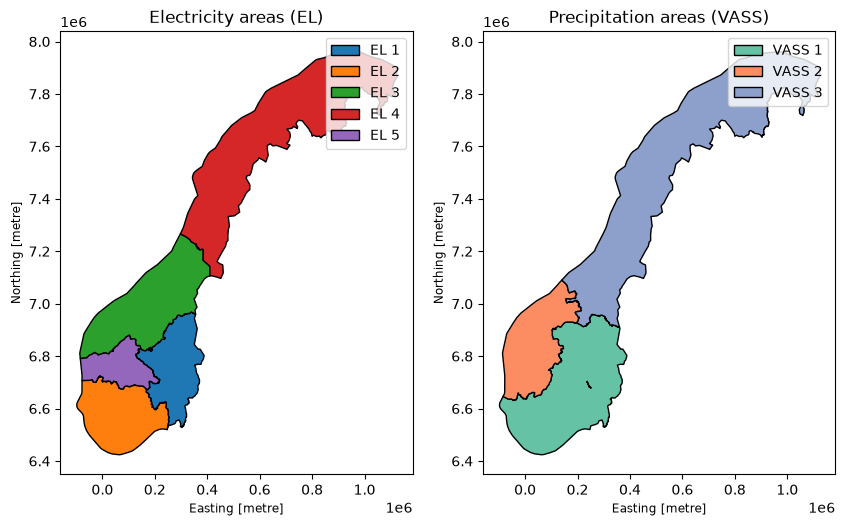

In [5]:
# Build one table of regions with the same labels as the Magasinstatistikk data
# ('EL 1'...'EL 5', 'VASS 1'...'VASS 3', 'NO 0'), so the weather data can later be
# matched with the area selector in the app.

# Electricity areas: 'NO 1' -> 'EL 1'
el = elspot[['budomr', 'geometry']].copy()
el['area'] = el['budomr'].str.replace('NO', 'EL')

# Precipitation areas: merge NVE regions per the task's hint
# (East = RS + RØ, North = RM + RN, West = RV)
vass_map = {'RØ': 'VASS 1', 'RS': 'VASS 1',
            'RV': 'VASS 2',
            'RM': 'VASS 3', 'RN': 'VASS 3'}
regions['area'] = regions['REGION'].map(vass_map)
print('Unmatched regions:', regions.loc[regions['area'].isna(), 'REGION'].tolist())  # should be []
vass = regions.dissolve(by='area').reset_index()[['area', 'geometry']]   # merge polygons

# Norway as a whole ('NO 0'): the union of all electricity areas
no0 = gpd.GeoDataFrame({'area': ['NO 0']}, geometry=[el.union_all()], crs=el.crs)

areas = pd.concat([el[['area', 'geometry']], vass, no0], ignore_index=True)
areas = gpd.GeoDataFrame(areas, crs=el.crs)
print(areas[['area']])

# Plot to check that the regions look right
fig, axes = plt.subplots(1, 2, figsize=(10, 7))
areas[areas['area'].str.startswith('EL')].plot(ax=axes[0], column='area', legend=True,
                                                cmap='tab10', edgecolor='black')
axes[0].set_title('Electricity areas (EL)')
areas[areas['area'].str.startswith('VASS')].plot(ax=axes[1], column='area', legend=True,
                                                  cmap='Set2', edgecolor='black')
axes[1].set_title('Precipitation areas (VASS)')
plt.show()

## Random locations per region
1000 random locations are sampled inside each region, to be used for the weather data download.

area
EL 1      1000
EL 2      1000
EL 3      1000
EL 4      1000
EL 5      1000
NO 0      1000
VASS 1    1000
VASS 2    1000
VASS 3    1000
dtype: int64


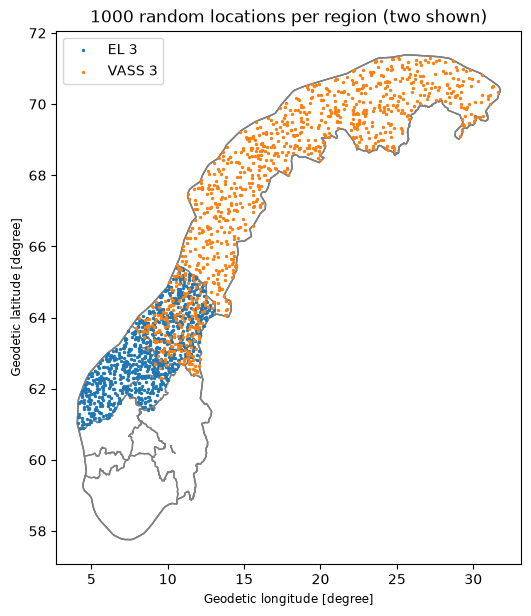

In [6]:
# Randomly sample 1000 locations inside each region.
# Sampling is done in UTM33 (metres, roughly equal-area), so the points are evenly spread
# over the area. A fixed seed makes the sample reproducible. Afterwards the points are
# converted to longitude/latitude (WGS84), which is what open-meteo expects.
N_POINTS = 1000
SEED = 320

rows = []
for i, row in areas.iterrows():
    pts = gpd.GeoSeries([row.geometry], crs=areas.crs).sample_points(N_POINTS, rng=SEED + i)
    pts = pts.explode(index_parts=False).to_crs(epsg=4326)   # MultiPoint -> points, -> lon/lat
    rows.append(pd.DataFrame({'area': row['area'], 'lon': pts.x.values, 'lat': pts.y.values}))

locations = pd.concat(rows, ignore_index=True)
print(locations.groupby('area').size())        # 1000 per area

# Save the locations so the Streamlit app can use the same points without the shapefiles
locations.to_csv('../project_data/locations.csv', index=False)

# Check visually: points for NO3 and VASS 3
ax = areas.to_crs(epsg=4326).plot(color='none', edgecolor='grey', figsize=(6, 8))
for a, c in [('EL 3', 'tab:blue'), ('VASS 3', 'tab:orange')]:
    sub = locations[locations['area'] == a]
    ax.scatter(sub['lon'], sub['lat'], s=2, color=c, label=a)
ax.legend()
ax.set_title('1000 random locations per region (two shown)')
plt.show()

## Weather data from open-meteo (ERA5)
Hourly historical reanalysis data (ERA5) is downloaded from open-meteo's archive API for the 1000 random locations in a region. ERA5 has a 0.25° grid, so many of the 1000 locations fall in the same grid cell and would return identical data. Each grid cell is therefore downloaded only once, and the regional average is weighted by the number of locations in each cell. This gives exactly the same average as using all 1000 locations, while staying within open-meteo's free API limits (600 calls/minute, 5000/hour, 10 000/day, where a request counts as roughly *locations × days / 14* calls).

In [7]:
# Download hourly ERA5 data from open-meteo for a region and a time interval
import time
import requests
import pandas as pd
from pathlib import Path

ARCHIVE_URL = "https://archive-api.open-meteo.com/v1/archive"
HOURLY_VARS = ['temperature_2m', 'precipitation', 'rain', 'snowfall',
               'relative_humidity_2m', 'wind_speed_10m', 'cloud_cover', 'shortwave_radiation']


def download_weather(area, start, end, locations=locations, variables=HOURLY_VARS, batch_size=20):
    """
    Download hourly ERA5 data for a region ('EL 3', 'VASS 1', ...) between start and end
    ('YYYY-MM-DD') and return the average over the region's random locations.
    """
    # Saved file from an earlier download is read instead of downloading again
    file = Path(f"../project_data/weather_{area.replace(' ', '')}_{start}_{end}.csv")
    if file.exists():
        return pd.read_csv(file, index_col='time', parse_dates=True)

    # Round the locations to the ERA5 0.25° grid and count the locations per grid cell
    pts = locations[locations['area'] == area]
    cells = (pts.assign(lat=(pts['lat'] * 4).round() / 4, lon=(pts['lon'] * 4).round() / 4)
                .groupby(['lat', 'lon']).size().rename('n').reset_index())
    print(f"{area}: {len(pts)} locations in {len(cells)} unique grid cells")

    frames = []
    for i in range(0, len(cells), batch_size):
        batch = cells.iloc[i:i + batch_size]
        params = {'latitude': ','.join(batch['lat'].astype(str)),
                  'longitude': ','.join(batch['lon'].astype(str)),
                  'start_date': start, 'end_date': end,
                  'hourly': ','.join(variables), 'models': 'era5', 'timezone': 'GMT'}

        # Request the batch; wait 5 minutes and try again when the API rate limit is reached
        r = requests.get(ARCHIVE_URL, params=params, timeout=300)
        while r.status_code == 429:
            print("  Rate limit reached, waiting 5 min ...", flush=True)
            time.sleep(300)
            r = requests.get(ARCHIVE_URL, params=params, timeout=300)
        r.raise_for_status()

        # One DataFrame per grid cell, with the number of locations in the cell as weight
        for n, loc in zip(batch['n'], r.json()):
            df = pd.DataFrame(loc['hourly'])
            df['n'] = n
            frames.append(df)
        print(f"  {min(i + batch_size, len(cells))}/{len(cells)} cells downloaded", flush=True)
        time.sleep(61)

    # Weighted average over the grid cells = average over all the region's locations
    data = pd.concat(frames)
    data['time'] = pd.to_datetime(data['time'])
    weather = (data[variables].multiply(data['n'], axis=0).groupby(data['time']).sum()
               .div(data.groupby('time')['n'].sum(), axis=0))
    weather.to_csv(file)
    return weather

In [8]:
# Download hourly data for NO3 (EL 3) for 2024
weather_no3 = download_weather('EL 3', '2024-01-01', '2024-12-31')
print(weather_no3.shape)
weather_no3.describe().round(2)

EL 3: 1000 locations in 298 unique grid cells
  20/298 cells downloaded
  40/298 cells downloaded
  60/298 cells downloaded
  80/298 cells downloaded
  100/298 cells downloaded
  120/298 cells downloaded
  140/298 cells downloaded
  160/298 cells downloaded
  180/298 cells downloaded
  200/298 cells downloaded
  220/298 cells downloaded
  240/298 cells downloaded
  Rate limit reached, waiting 5 min ...
  Rate limit reached, waiting 5 min ...
  Rate limit reached, waiting 5 min ...
  Rate limit reached, waiting 5 min ...
  Rate limit reached, waiting 5 min ...
  Rate limit reached, waiting 5 min ...
  Rate limit reached, waiting 5 min ...
  Rate limit reached, waiting 5 min ...
  Rate limit reached, waiting 5 min ...
  260/298 cells downloaded
  280/298 cells downloaded
  298/298 cells downloaded
(8784, 8)


,temperature_2m,precipitation,rain,snowfall,relative_humidity_2m,wind_speed_10m,cloud_cover,shortwave_radiation
count,8784.00,8784.00,8784.00,8784.00,8784.00,8784.00,8784.00,8784.00
mean,5.80,0.20,0.17,0.02,78.98,14.91,76.84,99.86
std,6.62,0.27,0.24,0.05,8.90,5.89,22.30,158.49
min,-11.31,0.00,0.00,0.00,44.00,3.64,1.53,0.00
25%,1.32,0.02,0.01,0.00,74.07,10.47,64.76,0.00
50%,5.44,0.10,0.07,0.00,80.75,13.77,83.33,4.29
75%,11.06,0.29,0.24,0.02,85.40,18.40,95.21,153.38
max,22.26,2.67,2.03,0.90,95.88,46.09,100.00,743.03
